# UrbanHub — Météo Open-Meteo (Rémi)
Open-Meteo Historical Weather API, modèle ECMWF IFS : Paris, Lyon et Lille. Données modélisées, horaires UTC. Les dates récentes sont actualisées en relançant le script. Les sorties officielles sont détaillées dans [le README](../README.md).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/openmeteo_batch.py').is_file())
files = sorted((root / 'data').glob('openmeteo-2020-01-01_*/gold/kpis/weather_hourly.parquet'))
if not files:
    raise FileNotFoundError('Lancer python scripts/openmeteo_batch.py depuis la racine')
hourly = pd.read_parquet(files[-1])
daily = pd.read_parquet(files[-1].with_name('weather_daily.parquet'))
display(hourly.groupby('city_id').agg(debut=('hour_utc', 'min'), fin=('hour_utc', 'max'), heures=('hour_utc', 'size'), visibilite=('visibility', 'count')))

,debut,fin,heures,visibilite
city_id,,,,
lille,2020-01-01 00:00:00+00:00,2026-11-19 14:00:00+00:00,60351,10144
lyon,2020-01-01 00:00:00+00:00,2026-11-19 14:00:00+00:00,60351,10144
paris,2020-01-01 00:00:00+00:00,2026-11-19 14:00:00+00:00,60351,10144


## Saisonnalité, extrêmes et épisodes inhabituels
Calcul sur les années civiles complètes. Les seuils P95 des maxima et P5 des minima quotidiens sont calculés par ville et saison. Les jours franchissant le même seuil à la suite forment un épisode. Il s’agit d’extrêmes relatifs à la période et au modèle, pas de normales climatiques ni de records observés en station.

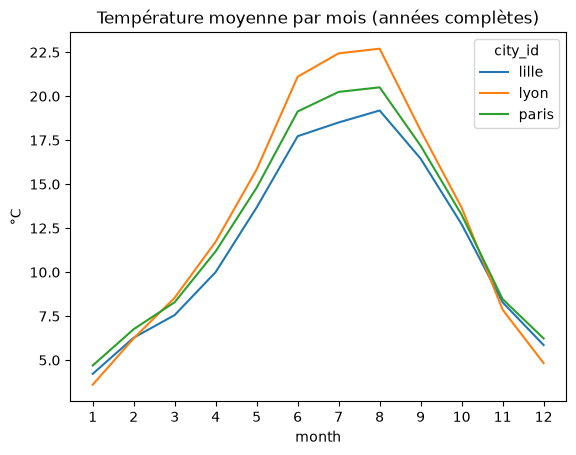

,city_id,day_utc,temperature_max
930,lille,2022-07-19 00:00:00+00:00,38.1
3846,lyon,2023-08-24 00:00:00+00:00,40.3
5960,paris,2022-07-19 00:00:00+00:00,39.1


,city_id,day_utc,temperature_min
405,lille,2021-02-09 00:00:00+00:00,-7.6
2925,lyon,2021-02-14 00:00:00+00:00,-7.0
6510,paris,2024-01-20 00:00:00+00:00,-6.1


,city_id,type,episode,debut,fin,jours
0,lyon,Chaud,130,2023-09-03 00:00:00+00:00,2023-09-12 00:00:00+00:00,10
1,lyon,Chaud,116,2022-05-14 00:00:00+00:00,2022-05-23 00:00:00+00:00,10
2,lille,Froid,90,2024-06-05 00:00:00+00:00,2024-06-13 00:00:00+00:00,9
3,paris,Froid,313,2024-06-05 00:00:00+00:00,2024-06-13 00:00:00+00:00,9
4,lille,Chaud,30,2023-09-04 00:00:00+00:00,2023-09-11 00:00:00+00:00,8
5,paris,Chaud,247,2023-09-03 00:00:00+00:00,2023-09-10 00:00:00+00:00,8
6,lille,Froid,65,2021-02-08 00:00:00+00:00,2021-02-14 00:00:00+00:00,7
7,paris,Chaud,221,2020-08-06 00:00:00+00:00,2020-08-12 00:00:00+00:00,7
8,lille,Froid,77,2022-12-12 00:00:00+00:00,2022-12-18 00:00:00+00:00,7
9,lyon,Chaud,108,2020-09-13 00:00:00+00:00,2020-09-19 00:00:00+00:00,7


In [2]:
year = hourly['hour_utc'].dt.year
days = daily.groupby([daily['day_utc'].dt.year, 'city_id']).size().unstack()
complete_years = days.index[days.min(axis=1).eq([366 if pd.Timestamp(y, 1, 1).is_leap_year else 365 for y in days.index]) & days.index.to_series().lt(year.max())]
series = hourly.loc[year.isin(complete_years)].copy()
series['month'] = series['hour_utc'].dt.month
monthly = series.pivot_table(index='month', columns='city_id', values='temperature')
monthly.plot(title='Température moyenne par mois (années complètes)', ylabel='°C', xticks=range(1, 13))
plt.show()
days = daily.loc[daily['day_utc'].dt.year.isin(complete_years) & daily['temperature_hours'].eq(24)].copy()
days['season'] = (days['day_utc'].dt.month % 12) // 3
group = days.groupby(['city_id', 'season'])
days['p95'] = group['temperature_max'].transform('quantile', q=.95)
days['p05'] = group['temperature_min'].transform('quantile', q=.05)
display(days.loc[days.groupby('city_id')['temperature_max'].idxmax(), ['city_id', 'day_utc', 'temperature_max']])
display(days.loc[days.groupby('city_id')['temperature_min'].idxmin(), ['city_id', 'day_utc', 'temperature_min']])
events = pd.concat([days[days['temperature_max'] > days['p95']].assign(type='Chaud'), days[days['temperature_min'] < days['p05']].assign(type='Froid')]).sort_values(['city_id', 'type', 'day_utc'])
events['episode'] = events.groupby(['city_id', 'type'])['day_utc'].diff().ne(pd.Timedelta(days=1)).cumsum()
display(events.groupby(['city_id', 'type', 'episode']).agg(debut=('day_utc', 'min'), fin=('day_utc', 'max'), jours=('day_utc', 'size')).sort_values('jours', ascending=False).head(10).reset_index())

## Visibilité
La visibilité est indisponible dans l’archive IFS de ce lot en 2020–2024 et partielle en 2025. Les corrélations portent uniquement sur les heures pour lesquelles elle est fournie ; aucune valeur n’est imputée.

In [3]:
rows = []
for city, frame in hourly.groupby('city_id'):
    for variable in ['temperature', 'wind_speed', 'precipitation']:
        pairs = frame[[variable, 'visibility']].dropna()
        r = pairs[variable].corr(pairs['visibility']) if len(pairs) > 1 and pairs.nunique().min() > 1 else float('nan')
        rows.append({'city_id': city, 'variable': variable, 'heures': len(pairs), 'pearson_r': r})
display(pd.DataFrame(rows).round(3))

,city_id,variable,heures,pearson_r
0,lille,temperature,10144,0.063
1,lille,wind_speed,10144,-0.107
2,lille,precipitation,10144,-0.390
3,lyon,temperature,10144,0.281
4,lyon,wind_speed,10144,0.168
5,lyon,precipitation,10144,-0.343
6,paris,temperature,10144,0.129
7,paris,wind_speed,10144,-0.084
8,paris,precipitation,10144,-0.407
